# Relative-time environment composites of robust MCSs: ocean versus land

Joins the **MCS track statistics** (`mcs_tracks_final_combined_*.parquet`) with the **environment circle means** that `scream/mcs_environment` extracts along every
track (`mcs_env_<source>_*.parquet`), selects the **robust MCS tracks** with the criteria of Paccini et al. (2026), splits them into **ocean** and **land** tracks with
`pf_landfrac`, and composites the environment by the time relative to MCS initiation for ERA5 (OBS), the 3-km CTL and TUNE SCREAM runs, the 25-km and the 100-km E3SM runs.
It follows `analyze_envvars_evolution.ipynb` of the GSRM repository and makes the two environment figures of the paper:
**(a) the distributions of the environment at initiation** (her Fig. 4) and **(b) the median evolution from 24 h before to 24 h after initiation** (her Fig. 5).

**How the data are joined.** The track file is read only for the periods (years) that the environment files contain and the environment file points to its track file in its
metadata (`tracks_file`), so the two always match. A track is identified by (`period`, `local_track`). The criteria are computed from the track statistics **in this notebook**
(vectorised, one row per track), the environment rows of the selected tracks are then composited on `time_offset_hours`.

**The environment.** One row per track, time and circle diameter. `time_offset_hours` is the **nominal** time relative to the first track time (0 = initiation) on the same grid for
every track (3-h steps for the 3-km runs, 1 h for the others). Before initiation the circle stays at the initial centroid, afterwards it follows the track centroid. The
environment is the nearest snapshot of the model / reanalysis (within half its time step). The circle diameter is `DIAMETER_KM` = 400 km, i.e. the **200-km radius of Fig. 5 (about the 2-degree radius of Fig. 4)**.
Circle means with less than `MIN_VALIDFRAC` of their area valid (850 hPa below the ground, relevant for land) are set to NaN.

### Selection of the robust MCSs

| | Paccini et al. (2026) | implemented here | `MCS_filter` of `compare_mcs_conditions.ipynb` (GSRM repo) |
|---|---|---|---|
| | tropics 30S-30N | `abs(meanlat at relative_step 0) <= 30` | the same |
| **surface** | lifetime cumulative land fraction < 10 % (ocean) | **Ocean**: lifetime maximum of `pf_landfrac` < 0.1; **Land**: lifetime minimum > 0.9; the rest is *Coastal* (not used) | `sum(pf_landfrac) < 0.1` (ocean only) |
| i | the first two time steps are non-MCS | `mcs_status == 0` at `relative_step` 0 and 1 | the first three steps |
| ii | MCS status continuous, no gaps | the steps with `mcs_status == 1` form one unbroken block | `sum(mcs_status) == mcs_duration` |
| iii | no start from a split, no end in a merger | `isnan(start_split_cloudnumber) & isnan(end_merge_cloudnumber)` | the split test and `start_status in (1, 2)`, `end_status in (0, 3)` |
| iv | the total rainfall peaks during MCS status | `mcs_status == 1` at the step of `max(total_rain)` | the same |
| v | duration not above the 95th percentile | `track_duration <= p95` of the tracks that pass all other criteria, **per source and surface** | not applied |

The **variants table** below counts the tracks that the choices of the last column would give, so that the effect of every difference is visible (the paper's text and the repository
code differ; the repository does not have the latest updates yet).

**How to use:** change only the *Configuration* cell (files of a source, diameter, filter parameters). More years of a source: list its new combined file (or a glob of yearly files) in `env_files`.
Run it on a compute node (measured 2026-11-21: 51 s and 4.4 GB peak memory with ERA5 2007-2017, the 3-km CTL run 1995-2005 and the three other sources).

In [1]:
import glob
import json
import os
import warnings

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

# Fonts: the same in all notebooks of this SCREAM / E3SM evaluation
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['mathtext.fontset'] = 'stix'

## Configuration
All user-editable items: where figures and tables go, the sources (environment files, optional track file, color), the circle diameter, the filter parameters and the variables
of the panels (in the order of the panels: row by row).

In [2]:
# ====================================================================================================================================
# CONFIGURATION (the only cell to edit)
# ====================================================================================================================================

# ---- Output ----------------------------------------------------------------------------------------------------------------------
figdir = '/pscratch/sd/f/feng045/mcs_env/figures/'       # figures and tables are written here (created if missing)
dpi = 200

# ---- Sources, in plotting order ----------------------------------------------------------------------------------------------------
# label         text in legends and tables
# env_files     environment Parquet files of mcs_environment (list; a name may contain wildcards, e.g. yearly files '.../mcs_env_OBS_20??.parquet')
# tracks_file   combined track-statistics Parquet file; None = the file named in the metadata of the environment file (the one the extraction used)
# color, linewidth   style of the source in every plot
ENV = '/pscratch/sd/f/feng045/mcs_env'                 # production folder of mcs_environment (one folder per source)
SOURCES = {
    'obs': dict(label='ERA5 (OBS)', env_files=[f'{ENV}/OBS/mcs_env_OBS_tropics_2007_2017.parquet'], tracks_file=None, color='black', linewidth=3.0),
    '3km_CTL': dict(label='3-km CTL', env_files=[f'{ENV}/3km_CTL/mcs_env_3km_CTL_tropics_1995_2005.parquet'], tracks_file=None,
                    color='dodgerblue', linewidth=1.8),
    '3km_TUNE': dict(label='3-km TUNE', env_files=[f'{ENV}/3km_TUNE/mcs_env_3km_TUNE_tropics_2019_2021.parquet'], tracks_file=None,
                     color='navy', linewidth=1.8),
    '25km': dict(label='25-km', env_files=[f'{ENV}/25km/mcs_env_25km_tropics_2009_2011.parquet'], tracks_file=None,
                 color='darkviolet', linewidth=1.8),
    '100km': dict(label='100-km', env_files=[f'{ENV}/100km/mcs_env_100km_tropics_2009_2020.parquet'], tracks_file=None,
                  color='saddlebrown', linewidth=1.8),
}
REF_SOURCE = 'obs'                 # key of SOURCES: the reference of the shading (interquartile range) in the median evolution plots

# ---- Environment circle ------------------------------------------------------------------------------------------------------------
DIAMETER_KM = 400                  # circle diameter in km (a value of the column diameter_km): 400 km = 200 km radius ~ the 2-degree radius of the paper
MIN_VALIDFRAC = 0.5                # a circle mean whose valid-area fraction (<var>_validfrac) is below this becomes NaN (850 hPa below the ground)

# ---- Robust-MCS selection (Paccini et al. 2026), see the table above -----------------------------------------------------------------
LAT_MAX = 30.0                     # tropics: |latitude of the first track point| <= LAT_MAX (degrees)
OCEAN_MAXFRAC = 0.1                # ocean track: the lifetime maximum of pf_landfrac is below this
LAND_MINFRAC = 0.9                 # land track: the lifetime minimum of pf_landfrac is above this (tracks in between are 'Coastal' and not used)
N_NONMCS = 2                       # the first N_NONMCS time steps of a track must be non-MCS (mcs_status == 0)
DURATION_PCT = 95.0                # a track must not last longer than this percentile of the durations of the other-criteria-passing tracks (None = no cut)

# ---- Composites -------------------------------------------------------------------------------------------------------------------
SURFACES = ['Ocean', 'Land']       # the surfaces that are composited and plotted
TIME_RANGE = (-24, 24)             # hours relative to initiation shown in the evolution plots
MIN_TRACKS_PER_BIN = 30            # a time bin with fewer valid values than this is left out of the evolution plots
MARKER_EVERY_H = 3                 # markers on the lines every MARKER_EVERY_H hours (the lines of hourly sources would be too crowded)
PDF_BINS = 40                      # number of bins of the distributions at initiation

# ---- Variables: name in the environment files -> label, unit and range of the distributions; the order is the order of the panels -----
VARIABLES = {
    'prw': dict(label='TCWV', unit='mm', pdf_range=(20, 75)),
    'omega850': dict(label=r'$\omega_{850\,\mathrm{hPa}}$', unit='Pa/s', pdf_range=(-0.7, 0.4)),
    'rh850': dict(label=r'RH$_{850\,\mathrm{hPa}}$', unit='%', pdf_range=(30, 105)),
    'q850': dict(label=r'Qv$_{850\,\mathrm{hPa}}$', unit='kg/kg', pdf_range=(0.004, 0.0195)),
    'omega500': dict(label=r'$\omega_{500\,\mathrm{hPa}}$', unit='Pa/s', pdf_range=(-0.7, 0.4)),
    'rh500': dict(label=r'RH$_{500\,\mathrm{hPa}}$', unit='%', pdf_range=(0, 105)),
}

## Load the environment and the tracks, and match them
Per source: the environment rows of the diameter, the track statistics of the same periods, and a check of how many tracks are found on both sides.

In [3]:
# Columns of the track-statistics file that the selection needs, and the key of a track
TRACK_COLUMNS = ['period', 'local_track', 'relative_step', 'track_duration', 'meanlat', 'mcs_status', 'mcs_duration', 'total_rain', 'pf_landfrac',
                 'start_split_cloudnumber', 'end_merge_cloudnumber', 'start_status', 'end_status']
KEY = ['period', 'local_track']


def expand_files(patterns):
    """
    Expand file names and wildcard patterns into a sorted list of existing files.

    Args:
        patterns: str or list of str
            File path(s); may contain wildcards.

    Returns:
        files: list of str
            Sorted, without duplicates.

    Raises:
        FileNotFoundError: a pattern matches no file (a wrong path must not give an empty source).
    """
    if isinstance(patterns, str):
        patterns = [patterns]
    files = []
    # Expand every pattern and keep the first occurrence of every file
    for pattern in patterns:
        matches = sorted(glob.glob(pattern))
        if not matches:
            raise FileNotFoundError(f'no file matches {pattern}')
        files.extend(m for m in matches if m not in files)
    return files


def read_env_metadata(path):
    """
    Read the JSON metadata (Parquet key 'mcs_env') that the extraction writes into its files: track file, periods, diameters, time step, ...

    Args:
        path: str
            Environment Parquet file.

    Returns:
        meta: dict
            Empty if the file has no such key.
    """
    raw = pq.ParquetFile(path).schema_arrow.metadata or {}
    return json.loads(raw[b'mcs_env']) if b'mcs_env' in raw else {}


def load_env(files, diameter_km, variables, min_validfrac):
    """
    Read the environment rows of one circle diameter from one or more extraction files.

    Args:
        files: list of str
            Environment Parquet files (one per year or a combined multi-year file).
        diameter_km: int
            Circle diameter to keep (a value of the column diameter_km).
        variables: list of str
            Variables wanted; those that a file does not have are skipped (for example no q850 in the 100-km run).
        min_validfrac: float
            A circle mean whose valid-area fraction (column <variable>_validfrac) is below this becomes NaN.

    Returns:
        env: DataFrame
            Columns period, local_track, time_offset_hours (float32) and one column per available variable; one row per track and time.
        info: dict
            'variables' (available ones, in the order of `variables`), 'periods' (sorted list of str), 'masked' (variable -> number of circle
            means set to NaN because of min_validfrac) and 'files'.

    Raises:
        ValueError: the files do not have the same variables, a file has no row of the diameter, or a (period, local_track, time_offset_hours)
            occurs twice.
    """
    frames = []
    available = None
    masked = {}
    # Loop over the files: read only the columns needed and only the rows of the diameter
    for path in files:
        names = pq.ParquetFile(path).schema_arrow.names
        have = [v for v in variables if v in names]
        if available is None:
            available = have
        elif have != available:
            raise ValueError(f'{path} has the variables {have}, the first file has {available}')
        columns = ['period', 'local_track', 'time_offset_hours', 'diameter_km'] + have + [f'{v}_validfrac' for v in have]
        df = pq.read_table(path, columns=columns, filters=[('diameter_km', '=', int(diameter_km))]).to_pandas()
        if len(df) == 0:
            raise ValueError(f'{path} has no row with diameter_km == {diameter_km}')
        # Mask the circle means that are mostly outside the valid area (counted per variable)
        for v in have:
            bad = df[f'{v}_validfrac'] < min_validfrac
            masked[v] = masked.get(v, 0) + int((bad & df[v].notna()).sum())
            df.loc[bad, v] = np.nan
        frames.append(df.drop(columns=['diameter_km'] + [f'{v}_validfrac' for v in have]))
    env = pd.concat(frames, ignore_index=True)
    env['time_offset_hours'] = env['time_offset_hours'].astype('float32')
    # The same track and time twice means that files overlap (for example a yearly and a combined file)
    if env.duplicated(KEY + ['time_offset_hours']).any():
        raise ValueError('some (period, local_track, time_offset_hours) occur more than once: the files overlap')
    info = dict(variables=available, periods=sorted(env['period'].unique()), masked=masked, files=list(files))
    return env, info


def load_tracks(tracks_file, periods, columns=TRACK_COLUMNS):
    """
    Read the track statistics (one row per track and time step) of the given periods.

    Args:
        tracks_file: str
            Combined track-statistics Parquet file.
        periods: list of str
            Periods (calendar year in which the track starts) to read; the row-group statistics are used to skip the other years.
        columns: list of str (default: TRACK_COLUMNS)
            Columns to read.

    Returns:
        tr: DataFrame

    Raises:
        ValueError: the file does not have all columns.
    """
    names = pq.ParquetFile(tracks_file).schema_arrow.names
    missing = [c for c in columns if c not in names]
    if missing:
        raise ValueError(f'{tracks_file} has no column(s) {missing}')
    return pq.read_table(tracks_file, columns=columns, filters=[('period', 'in', list(periods))]).to_pandas()

In [4]:
# Environment and track summaries of every source (the summaries come from the selection cells below)
ENVD, TRACKS_FILE, INFO = {}, {}, {}
TRACKS = {}
report = []

# Loop over the sources: environment rows, the matching track statistics, and the match report
for key, cfg in SOURCES.items():
    files = expand_files(cfg['env_files'])
    env, info = load_env(files, DIAMETER_KM, list(VARIABLES), MIN_VALIDFRAC)
    meta = read_env_metadata(files[0])
    tracks_file = cfg.get('tracks_file') or meta.get('tracks_file')
    if not tracks_file:
        raise ValueError(f"{cfg['label']}: no tracks_file in SOURCES and none in the metadata of {files[0]}")
    tr = load_tracks(tracks_file, info['periods'])
    # Match: every track of the environment must be in the track file; tracks without environment rows are the ones the extraction had to skip
    env_keys = env[KEY].drop_duplicates()
    track_keys = tr[KEY].drop_duplicates()
    both = env_keys.merge(track_keys, on=KEY, how='left', indicator=True)
    share_env = float((both['_merge'] == 'both').mean())
    both2 = track_keys.merge(env_keys, on=KEY, how='left', indicator=True)
    share_tr = float((both2['_merge'] == 'both').mean())
    if share_env < 0.999:
        raise ValueError(f"{cfg['label']}: only {share_env:.4%} of the environment tracks are in {tracks_file} (wrong track file or periods?)")
    ENVD[key], TRACKS_FILE[key], INFO[key], TRACKS[key] = env, tracks_file, info, tr
    valid = {v: float(env[v].notna().mean()) for v in info['variables']}
    report.append(dict(source=cfg['label'], periods=f"{info['periods'][0]}-{info['periods'][-1]}", env_rows=len(env), env_tracks=len(env_keys),
                       track_rows=len(tr), tracks_in_file=len(track_keys), env_tracks_in_track_file=f'{share_env:.3%}',
                       track_file_tracks_with_env=f'{share_tr:.3%}', variables=', '.join(info['variables']),
                       **{f'valid {v} (%)': round(100 * s, 1) for v, s in valid.items()}))
    print(f"{cfg['label']:>11s}: {len(files)} file(s), periods {info['periods'][0]}-{info['periods'][-1]}, {len(env):,} env rows, {len(env_keys):,} tracks, "
          f"matched {share_env:.3%} (tracks of the track file with env rows {share_tr:.3%}); circle means masked by MIN_VALIDFRAC: {info['masked']}")

display(pd.DataFrame(report).set_index('source').T)

 ERA5 (OBS): 1 file(s), periods 2007-2017, 14,113,973 env rows, 337,321 tracks, matched 100.000% (tracks of the track file with env rows 100.000%); circle means masked by MIN_VALIDFRAC: {'prw': 0, 'omega850': 107016, 'rh850': 107016, 'q850': 107016, 'omega500': 0, 'rh500': 0}
   3-km CTL: 1 file(s), periods 1995-2005, 5,898,522 env rows, 413,609 tracks, matched 100.000% (tracks of the track file with env rows 100.000%); circle means masked by MIN_VALIDFRAC: {'prw': 0, 'omega850': 1833, 'rh850': 1833, 'q850': 1833, 'omega500': 0, 'rh500': 0}
  3-km TUNE: 1 file(s), periods 2019-2021, 746,511 env rows, 54,010 tracks, matched 100.000% (tracks of the track file with env rows 100.000%); circle means masked by MIN_VALIDFRAC: {'prw': 0, 'omega850': 393, 'rh850': 393, 'q850': 393, 'omega500': 0, 'rh500': 0}
      25-km: 1 file(s), periods 2009-2011, 3,211,068 env rows, 66,786 tracks, matched 100.000% (tracks of the track file with env rows 100.000%); circle means masked by MIN_VALIDFRAC: {'prw

source,ERA5 (OBS),3-km CTL,3-km TUNE,25-km,100-km
periods,2007-2017,1995-2005,2019-2021,2009-2011,2009-2020
env_rows,14113973,5898522,746511,3211068,2009473
env_tracks,337321,413609,54010,66786,30998
track_rows,6017124,7358524,889852,1608183,1265521
tracks_in_file,337321,413609,54010,66786,30998
env_tracks_in_track_file,100.000%,100.000%,100.000%,100.000%,100.000%
track_file_tracks_with_env,100.000%,100.000%,100.000%,100.000%,100.000%
variables,"prw, omega850, rh850, q850, omega500, rh500","prw, omega850, rh850, q850, omega500, rh500","prw, omega850, rh850, q850, omega500, rh500","prw, rh850, q850, omega500, rh500","prw, rh850, omega500"
valid prw (%),100.0,99.9,42.9,100.0,100.0
valid omega850 (%),99.2,99.9,99.9,NaN,NaN


## Select the robust MCSs
`summarize_tracks` reduces the track statistics to **one row per track** (all quantities the criteria need); `apply_criteria` turns that table into a flag per criterion and the
surface class. Splitting them lets the variants table below try other choices without reading the tracks again. The table of criteria is in the first cell of this notebook.

In [5]:
def summarize_tracks(tr):
    """
    Reduce the track statistics (one row per track and time step) to one row per track with every quantity that the selection criteria use.

    Args:
        tr: DataFrame
            Columns of TRACK_COLUMNS, one row per track and time step (any order).

    Returns:
        t: DataFrame
            Index (period, local_track); columns n_steps, duration (hours), lat0 (meanlat at relative_step 0), lf_min / lf_max / lf_sum (lifetime
            statistics of pf_landfrac; steps without a precipitation feature are skipped), start_split / end_merge (cloud numbers, NaN = none),
            start_status, end_status, mcs_duration, n_mcs (steps with mcs_status == 1), first_mcs / last_mcs (relative_step of the first / last MCS
            step), lead_nonmcs (steps before the first MCS step) and peak_status (mcs_status at the step of the largest total_rain; NaN without rain data).
    """
    tr = tr.reset_index(drop=True)
    g = tr.groupby(KEY, sort=False)
    # Per-track variables (constant within a track) and the lifetime statistics of the land fraction (NaN steps are skipped)
    t = g.agg(n_steps=('relative_step', 'size'), duration=('track_duration', 'first'), lf_min=('pf_landfrac', 'min'), lf_max=('pf_landfrac', 'max'),
              lf_sum=('pf_landfrac', 'sum'), start_split=('start_split_cloudnumber', 'first'), end_merge=('end_merge_cloudnumber', 'first'),
              start_status=('start_status', 'first'), end_status=('end_status', 'first'), mcs_duration=('mcs_duration', 'first'),
              n_rain=('total_rain', 'count'))
    # Latitude of the first track point (the row with relative_step == 0; NaN if that point has no position)
    t['lat0'] = tr.loc[tr['relative_step'] == 0].set_index(KEY)['meanlat'].reindex(t.index)
    # The MCS steps: how many, where they start and end (the block is unbroken if last - first + 1 == count); steps before the first one are non-MCS
    mcs = tr.loc[tr['mcs_status'] == 1].groupby(KEY, sort=False)['relative_step'].agg(first_mcs='min', last_mcs='max', n_mcs='size')
    t = t.join(mcs)
    t['n_mcs'] = t['n_mcs'].fillna(0).astype(int)
    t['lead_nonmcs'] = t['first_mcs'].fillna(t['n_steps']).astype(int)
    # The MCS status at the step of the largest total rain (steps without rain data cannot be the maximum)
    rain = tr['total_rain'].fillna(-np.inf)
    idx = rain.groupby([tr['period'], tr['local_track']], sort=False).idxmax()
    t['peak_status'] = pd.Series(tr['mcs_status'].to_numpy()[idx.to_numpy()], index=idx.index).where(t['n_rain'] > 0)
    return t.drop(columns=['n_rain'])


def apply_criteria(t, lat_max=LAT_MAX, ocean_max=OCEAN_MAXFRAC, land_min=LAND_MINFRAC, n_nonmcs=N_NONMCS, duration_pct=DURATION_PCT,
                   continuity='contiguous', split_merge='nan', ocean_rule='max'):
    """
    Apply the robust-MCS criteria to the one-row-per-track table.

    Args:
        t: DataFrame
            Output of summarize_tracks.
        lat_max: float (default: LAT_MAX)
            Tropics limit in degrees.
        ocean_max, land_min: float (default: OCEAN_MAXFRAC, LAND_MINFRAC)
            Ocean: land fraction statistic below ocean_max; land: lifetime minimum above land_min; else 'Coastal'.
        n_nonmcs: int (default: N_NONMCS)
            Number of leading time steps that must be non-MCS.
        duration_pct: float or None (default: DURATION_PCT)
            Percentile of the durations (per surface, of the tracks that pass all other criteria) that a track must not exceed; None = no cut.
        continuity: str (default: 'contiguous')
            'contiguous': the MCS steps form one unbroken block (paper); 'mcs_duration': sum(mcs_status) == mcs_duration (GSRM repository code).
        split_merge: str (default: 'nan')
            'nan': start_split_cloudnumber and end_merge_cloudnumber are NaN; 'status': start_split is NaN, start_status in (1, 2) and
            end_status in (0, 3) (GSRM repository code).
        ocean_rule: str (default: 'max')
            'max': the lifetime maximum of pf_landfrac is below ocean_max; 'sum': the lifetime sum is (paper wording / GSRM repository code).

    Returns:
        flags: DataFrame
            Same index as t; columns duration, surface ('Ocean' / 'Land' / 'Coastal'), tropics, nonmcs_start, continuous, no_split_merge,
            peak_in_mcs, duration_cut (the percentile of the track's surface, NaN without cut), duration_ok and robust (all criteria).

    Raises:
        ValueError: an unknown continuity, split_merge or ocean_rule.
    """
    if continuity not in ('contiguous', 'mcs_duration') or split_merge not in ('nan', 'status') or ocean_rule not in ('max', 'sum'):
        raise ValueError(f'unknown option: continuity={continuity}, split_merge={split_merge}, ocean_rule={ocean_rule}')
    f = pd.DataFrame(index=t.index)
    f['duration'] = t['duration']
    # Surface class from the lifetime land fraction (NaN comparisons are False, so a track without any land fraction is 'Coastal')
    is_ocean = (t['lf_max'] if ocean_rule == 'max' else t['lf_sum']) < ocean_max
    is_land = t['lf_min'] > land_min
    f['surface'] = np.where(is_ocean, 'Ocean', np.where(is_land, 'Land', 'Coastal'))
    # One flag per criterion
    f['tropics'] = t['lat0'].abs() <= lat_max
    f['nonmcs_start'] = t['lead_nonmcs'] >= n_nonmcs
    if continuity == 'contiguous':
        f['continuous'] = (t['n_mcs'] > 0) & ((t['last_mcs'] - t['first_mcs'] + 1) == t['n_mcs'])
    else:
        f['continuous'] = t['n_mcs'] == t['mcs_duration']
    f['no_split_merge'] = t['start_split'].isna() & t['end_merge'].isna()
    if split_merge == 'status':
        f['no_split_merge'] = t['start_split'].isna() & t['start_status'].isin([1, 2]) & t['end_status'].isin([0, 3])
    f['peak_in_mcs'] = t['peak_status'] == 1
    # The duration cut: a percentile of the durations of the tracks that pass everything else, separately for every surface
    others = f['tropics'] & f['surface'].isin(['Ocean', 'Land']) & f['nonmcs_start'] & f['continuous'] & f['no_split_merge'] & f['peak_in_mcs']
    f['duration_cut'] = np.nan
    if duration_pct is None:
        f['duration_ok'] = True
    else:
        cut = {s: t.loc[others & (f['surface'] == s), 'duration'].quantile(duration_pct / 100.0) for s in ('Ocean', 'Land')}
        f['duration_cut'] = f['surface'].map(cut).astype(float)
        f['duration_ok'] = f['duration'] <= f['duration_cut']
    f['robust'] = others & f['duration_ok']
    return f


def select_robust_tracks(tr, **kwargs):
    """
    Robust-MCS selection from the track statistics in one call: summarize_tracks followed by apply_criteria.

    Args:
        tr: DataFrame
            Track statistics (columns of TRACK_COLUMNS, one row per track and time step).
        **kwargs:
            Options of apply_criteria.

    Returns:
        flags: DataFrame
            See apply_criteria.
    """
    return apply_criteria(summarize_tracks(tr), **kwargs)


FUNNEL_COLUMNS = ['surface', 'tropics', 'nonmcs_start', 'continuous', 'no_split_merge', 'peak_in_mcs', 'duration_ok']


def funnel_counts(flags, surfaces=SURFACES):
    """
    Number of tracks left after every criterion, applied one after the other.

    Args:
        flags: DataFrame
            Output of apply_criteria.
        surfaces: list of str (default: SURFACES)
            Surfaces (rows of the result).

    Returns:
        counts: DataFrame
            One row per surface; columns 'all tracks' (the same number in every row), then FUNNEL_COLUMNS: 'surface' = the tracks of that surface,
            then each column the tracks that also pass this and all earlier criteria. The last column is the number of robust tracks.
    """
    rows = {}
    # One row per surface: start with the tracks of the surface and keep only those that also pass the next criterion
    for s in surfaces:
        keep = flags['surface'] == s
        row = {'all tracks': len(flags), 'surface': int(keep.sum())}
        for col in FUNNEL_COLUMNS[1:]:
            keep = keep & flags[col]
            row[col] = int(keep.sum())
        rows[s] = row
    return pd.DataFrame(rows).T


# The choices of the GSRM repository code (last column of the table above), one at a time and all together
VARIANTS = {
    'this notebook (paper wording)': {},
    '3 initial non-MCS steps': dict(n_nonmcs=3),
    'continuity: sum(mcs_status) == mcs_duration': dict(continuity='mcs_duration'),
    'split / merge also by the status codes': dict(split_merge='status'),
    'ocean: sum(pf_landfrac) < 0.1': dict(ocean_rule='sum'),
    'no duration cut': dict(duration_pct=None),
    'all of the above (GSRM repository code)': dict(n_nonmcs=3, continuity='mcs_duration', split_merge='status', ocean_rule='sum', duration_pct=None),
}


def variants_table(summaries, variants=VARIANTS, surfaces=SURFACES):
    """
    Number of robust tracks per source and surface under the variants of the criteria.

    Args:
        summaries: dict
            source label -> output of summarize_tracks.
        variants: dict (default: VARIANTS)
            Variant name -> options of apply_criteria (the rest keeps the defaults of the configuration).
        surfaces: list of str (default: SURFACES)
            Surfaces (columns, with the source).

    Returns:
        table: DataFrame
            Rows = variants, columns = (source, surface).
    """
    records = []
    # Every source and variant: apply the criteria to the per-track table and count the robust tracks of every surface
    for label, t in summaries.items():
        for name, options in variants.items():
            f = apply_criteria(t, **options)
            for s in surfaces:
                records.append(dict(variant=name, source=label, surface=s, n=int((f['robust'] & (f['surface'] == s)).sum())))
    table = pd.DataFrame(records).pivot(index='variant', columns=['source', 'surface'], values='n')
    # Rows in the order of the variants, columns in the order of the sources and surfaces
    return table.reindex(index=list(variants), columns=pd.MultiIndex.from_tuples([(l, s) for l in summaries for s in surfaces], names=['source', 'surface']))

In [6]:
# One row per track and the flags of the criteria, per source (the track statistics are not needed afterwards)
SUMM, FLAGS = {}, {}
for key, cfg in SOURCES.items():
    SUMM[key] = summarize_tracks(TRACKS[key])
    FLAGS[key] = apply_criteria(SUMM[key])
    TRACKS[key] = None                                        # free the memory of the time-step table

# The funnel: tracks left after every criterion, applied one after the other
funnel = pd.concat({SOURCES[k]['label']: funnel_counts(FLAGS[k]) for k in SOURCES}, names=['source', 'surface'])
funnel = funnel.rename(columns={'surface': 'tracks of the surface', 'tropics': 'tropics', 'nonmcs_start': f'first {N_NONMCS} steps non-MCS', 'continuous': 'continuous MCS',
                                'no_split_merge': 'no split / merge', 'peak_in_mcs': 'rain peak in MCS',
                                'duration_ok': f'duration <= p{DURATION_PCT:g}'})
cut = pd.concat({SOURCES[k]['label']: FLAGS[k].groupby('surface')['duration_cut'].first().reindex(SURFACES) for k in SOURCES}, names=['source', 'surface'])
funnel[f'p{DURATION_PCT:g} (h)'] = cut
print('Tracks left after every criterion (applied in this order; the last count is the number of robust tracks):')
display(funnel)

Tracks left after every criterion (applied in this order; the last count is the number of robust tracks):


all tracks  tracks of the surface  tropics  \
source     surface                                               
ERA5 (OBS) Ocean        337321                 146452   146450   
           Land         337321                  80960    80957   
3-km CTL   Ocean        413609                 207669   207665   
           Land         413609                 105510   105506   
3-km TUNE  Ocean         54010                  26139    26139   
           Land          54010                  11986    11986   
25-km      Ocean         66786                  23261    23260   
           Land          66786                  27036    27036   
100-km     Ocean         30998                  11443    11435   
           Land          30998                  11133    11132   

                    first 2 steps non-MCS  continuous MCS  no split / merge  \
source     surface                                                            
ERA5 (OBS) Ocean                    83452           68817             38831   
           Land                     57630           50330             34416   
3-km CTL   Ocean                   108623           68646             28736   
           Land                     58817           52603             33924   
3-km TUNE  Ocean                    14123            9750              4582   
           Land                      7250            6296              3901   
25-km      Ocean                     7018            5141              1292   
           Land                      7291            5594              1484   
100-km     Ocean                     1515            1413               778   
           Land                      1597            1476               948   

                    rain peak in MCS  duration <= p95  p95 (h)  
source     surface                                              
ERA5 (OBS) Ocean               36911            35107    39.00  
           Land                33049            31404    29.00  
3-km CTL   Ocean               24808            23570    30.00  
           Land                29021            27702    26.00  
3-km TUNE  Ocean                4134             3933    31.00  
           Land                 3362             3197    27.00  
25-km      Ocean                 948              901    64.00  
           Land                 1246             1183    44.75  
100-km     Ocean                 777              739   103.00  
           Land                  943              895    66.90

### Variants of the criteria
Robust tracks per source and surface under the choices of the GSRM repository code (see the table at the top), one at a time and all together. The first row is what the rest of the notebook uses.

In [7]:
variants = variants_table({SOURCES[k]['label']: SUMM[k] for k in SOURCES})
display(variants)

# Robust track lists of the sources: saved for other analyses
os.makedirs(figdir, exist_ok=True)
for key in SOURCES:
    f = FLAGS[key]
    f.loc[f['robust'] & f['surface'].isin(SURFACES), ['surface', 'duration']].reset_index().to_parquet(os.path.join(figdir, f'robust_tracks_{key}.parquet'))

source                                      ERA5 (OBS)        3-km CTL         \
surface                                          Ocean   Land    Ocean   Land   
variant                                                                         
this notebook (paper wording)                    35107  31404    23570  27702   
3 initial non-MCS steps                          31426  22260    18735  14153   
continuity: sum(mcs_status) == mcs_duration      36636  32462    26072  28370   
split / merge also by the status codes           34871  31310    23356  27519   
ocean: sum(pf_landfrac) < 0.1                    33644  31404    22845  27702   
no duration cut                                  36911  33049    24808  29021   
all of the above (GSRM repository code)          32698  24008    20863  15067   

source                                      3-km TUNE       25-km        \
surface                                         Ocean  Land Ocean  Land   
variant                                                                   
this notebook (paper wording)                    3933  3197   901  1183   
3 initial non-MCS steps                          3036  1884   805   849   
continuity: sum(mcs_status) == mcs_duration      4174  3276  1063  1326   
split / merge also by the status codes           3896  3169   894  1179   
ocean: sum(pf_landfrac) < 0.1                    3783  3197   891  1183   
no duration cut                                  4134  3362   948  1246   
all of the above (GSRM repository code)          3242  2022   988   993   

source                                      100-km       
surface                                      Ocean Land  
variant                                                  
this notebook (paper wording)                  739  895  
3 initial non-MCS steps                        246  280  
continuity: sum(mcs_status) == mcs_duration    763  925  
split / merge also by the status codes         739  895  
ocean: sum(pf_landfrac) < 0.1                  697  895  
no duration cut                                777  943  
all of the above (GSRM repository code)        249  303

## Composites by the time relative to initiation
For every surface the environment rows of the robust tracks are grouped by the exact `time_offset_hours` (the nominal grid: the same bins for all tracks). Per bin: the median, the
quartiles, the mean, the number of valid values and the number of tracks. The distributions at initiation use the rows at offset 0.

In [8]:
def composite_by_offset(df, variables, offset_col='time_offset_hours', min_count=1):
    """
    Median, quartiles, mean and counts of variables in bins of the time relative to initiation.

    Args:
        df: DataFrame
            One row per track and time; columns offset_col and the variables (NaN = missing).
        variables: list of str
            Variables to composite (columns of df).
        offset_col: str (default: 'time_offset_hours')
            Column with the time relative to initiation; every distinct value is a bin.
        min_count: int (default: 1)
            A bin with fewer valid values than this gets NaN statistics (the counts are kept).

    Returns:
        comp: DataFrame
            Long table with columns offset_col, variable, median, q25, q75, mean, count (valid values) and n_tracks (rows of the bin).
    """
    g = df.groupby(offset_col)
    parts = []
    # One block per variable: the statistics of all bins at once
    for v in variables:
        s = g[v]
        part = pd.DataFrame({'median': s.median(), 'q25': s.quantile(0.25), 'q75': s.quantile(0.75), 'mean': s.mean(), 'count': s.count()})
        part['variable'] = v
        parts.append(part)
    comp = pd.concat(parts).reset_index()
    comp['n_tracks'] = comp[offset_col].map(g.size())
    # Bins with too few valid values: no statistics
    comp.loc[comp['count'] < min_count, ['median', 'q25', 'q75', 'mean']] = np.nan
    return comp


def env_of_selected(env, flags, surface):
    """
    Environment rows of the robust tracks of one surface.

    Args:
        env: DataFrame
            Output of load_env.
        flags: DataFrame
            Output of apply_criteria (index period, local_track).
        surface: str
            'Ocean' or 'Land'.

    Returns:
        d: DataFrame
            The rows of env whose track is robust and of this surface.
    """
    ids = flags.loc[flags['robust'] & (flags['surface'] == surface)].index.to_frame(index=False)
    return env.merge(ids, on=KEY, how='inner')


def relative_frequency(values, lo, hi, nbins):
    """
    Relative-frequency distribution of values (percent of all valid values per bin).

    Args:
        values: array-like
            Values; NaN / inf are ignored.
        lo, hi: float
            Range of the bins.
        nbins: int
            Number of equal bins.

    Returns:
        centers: ndarray (nbins,)
        freq: ndarray (nbins,)
            Percent of the valid values in every bin (values outside [lo, hi] are counted in the total, not in a bin).
        n: int
            Number of valid values.
    """
    v = np.asarray(values, dtype=float)
    v = v[np.isfinite(v)]
    edges = np.linspace(lo, hi, nbins + 1)
    counts, _ = np.histogram(v, bins=edges)
    return 0.5 * (edges[:-1] + edges[1:]), 100.0 * counts / max(v.size, 1), int(v.size)

In [9]:
COMP, INIT, NSEL = {}, {}, {}
rows = []
# Per source and surface: the composite table, the values at initiation (offset 0) and a check that all tracks are in the bins before initiation
for key, cfg in SOURCES.items():
    variables = INFO[key]['variables']
    tables = []
    for surface in SURFACES:
        d = env_of_selected(ENVD[key], FLAGS[key], surface)
        n = d[KEY].drop_duplicates().shape[0]
        NSEL[(key, surface)] = n
        comp = composite_by_offset(d, variables, min_count=MIN_TRACKS_PER_BIN)
        comp.insert(0, 'surface', surface)
        tables.append(comp)
        INIT[(key, surface)] = d.loc[d['time_offset_hours'] == 0, KEY + variables]
        # Bins from -24 h to 0: every selected track should be there (fewer only for tracks that start within 24 h of the start of the environment record)
        pre = comp[(comp['time_offset_hours'] <= 0) & (comp['variable'] == variables[0])]
        rows.append(dict(source=cfg['label'], surface=surface, robust_tracks=n, tracks_at_offset_0=int(INIT[(key, surface)].shape[0]),
                         min_tracks_per_bin_before_0=int(pre['n_tracks'].min()) if len(pre) else 0,
                         env_rows_of_selected=len(d),
                         **{f'valid {v} at 0 h (%)': round(100 * float(INIT[(key, surface)][v].notna().mean()), 1) for v in variables}))
    COMP[key] = pd.concat(tables, ignore_index=True)
display(pd.DataFrame(rows).set_index(['source', 'surface']))

# The composite tables of all sources (one CSV per surface) for other plots
for surface in SURFACES:
    pd.concat({SOURCES[k]['label']: COMP[k][COMP[k]['surface'] == surface].drop(columns='surface') for k in SOURCES},
              names=['source']).reset_index(level=0).to_csv(os.path.join(figdir, f'composites_{surface.lower()}.csv'), index=False)

robust_tracks  tracks_at_offset_0  \
source     surface                                      
ERA5 (OBS) Ocean            35107               35107   
           Land             31404               31404   
3-km CTL   Ocean            23570               23570   
           Land             27702               27702   
3-km TUNE  Ocean             3933                3933   
           Land              3197                3197   
25-km      Ocean              901                 901   
           Land              1183                1183   
100-km     Ocean              739                 739   
           Land               895                 895   

                    min_tracks_per_bin_before_0  env_rows_of_selected  \
source     surface                                                      
ERA5 (OBS) Ocean                          35107               1516516   
           Land                           31404               1228829   
3-km CTL   Ocean                          23570                323813   
           Land                           27702                357975   
3-km TUNE  Ocean                           3933                 53696   
           Land                            3197                 41814   
25-km      Ocean                            901                 47784   
           Land                            1183                 56123   
100-km     Ocean                            739                 49235   
           Land                             895                 44672   

                    valid prw at 0 h (%)  valid omega850 at 0 h (%)  \
source     surface                                                    
ERA5 (OBS) Ocean                   100.0                      100.0   
           Land                    100.0                       96.3   
3-km CTL   Ocean                    99.9                      100.0   
           Land                     99.9                       99.8   
3-km TUNE  Ocean                    42.9                      100.0   
           Land                     42.3                       99.8   
25-km      Ocean                   100.0                        NaN   
           Land                    100.0                        NaN   
100-km     Ocean                   100.0                        NaN   
           Land                    100.0                        NaN   

                    valid rh850 at 0 h (%)  valid q850 at 0 h (%)  \
source     surface                                                  
ERA5 (OBS) Ocean                     100.0                  100.0   
           Land                       96.3                   96.3   
3-km CTL   Ocean                     100.0                  100.0   
           Land                       99.8                   99.8   
3-km TUNE  Ocean                     100.0                  100.0   
           Land                       99.8                   99.8   
25-km      Ocean                     100.0                  100.0   
           Land                       87.8                   87.8   
100-km     Ocean                     100.0                    NaN   
           Land                       90.3                    NaN   

                    valid omega500 at 0 h (%)  valid rh500 at 0 h (%)  
source     surface                                                     
ERA5 (OBS) Ocean                        100.0                   100.0  
           Land                         100.0                   100.0  
3-km CTL   Ocean                        100.0                   100.0  
           Land                          99.9                    99.9  
3-km TUNE  Ocean                        100.0                   100.0  
           Land                         100.0                   100.0  
25-km      Ocean                        100.0                   100.0  
           Land                         100.0                   100.0  
100-km     Ocean                        100.0           

## Figures
The style follows the paper: panel letters, the variable as title, the unit on the y axis, the dotted line at initiation, ERA5 in black. Panels: TCWV, omega850, RH850 / Qv850, omega500, RH500
(the paper's B<sub>L,CAPE</sub> and B<sub>L,SUBSAT</sub> are not available here; the two relative humidities take their place). Sources that do not have a variable (the 100-km run has no
Qv850, RH500 and omega850, the 25-km run no omega850) are missing from that panel. All figures are saved in `figdir` (24-bit PNG).

In [15]:
def save_figure(fig, name, directory=None, dpi_out=None):
    """
    Save a figure as a 24-bit PNG (RGB, no alpha channel).

    Args:
        fig: matplotlib Figure
        name: str
            File name (with .png).
        directory: str (default: figdir)
            Output folder (created if missing).
        dpi_out: int (default: dpi)
            Resolution.

    Returns:
        path: str
    """
    from PIL import Image
    directory = directory or figdir
    os.makedirs(directory, exist_ok=True)
    path = os.path.join(directory, name)
    fig.savefig(path, dpi=dpi_out or dpi, bbox_inches='tight', facecolor='white')
    Image.open(path).convert('RGB').save(path)
    return path


def _style_axes(ax, dashed_grid=False):
    """
    Style of the paper: no top and right spines and a grid.

    Args:
        ax: matplotlib Axes
        dashed_grid: bool (default: False)
            False: a light solid grid under everything. True (time-series plots and distributions): a darker dotted grid that is drawn above the shaded band
            (patches) and below the lines, so that it stays visible on the shading.
    """
    ax.spines[['top', 'right']].set_visible(False)
    if dashed_grid:
        ax.grid(True, color='0.55', linestyle=':', linewidth=0.5, alpha=0.75)
        ax.set_axisbelow('line')
    else:
        ax.grid(True, color='0.85', linewidth=0.5)
        ax.set_axisbelow(True)


def _source_legend(fig, handles, labels, ncol=3):
    """Legend below the panels (the sources with their number of tracks and the dotted initiation line)."""
    fig.legend(handles, labels, loc='lower center', ncol=ncol, frameon=True, fontsize=10, bbox_to_anchor=(0.5, 0.0))


def plot_distributions(init, surface, sources=None, nbins=None):
    """
    Distributions of the environment at initiation (the style of Fig. 4 of the paper): relative frequency of the circle means at time offset 0.

    Args:
        init: dict
            (source key, surface) -> DataFrame with the variables at offset 0 (one row per track).
        surface: str
            'Ocean' or 'Land'.
        sources: dict (default: SOURCES)
            Sources, in plotting order (label, color, linewidth).
        nbins: int (default: PDF_BINS)
            Number of bins of the distributions.

    Returns:
        fig: matplotlib Figure
    """
    sources = sources or SOURCES
    nbins = nbins or PDF_BINS
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
    handles, labels = {}, {}
    # One panel per variable, one line per source that has the variable
    for ax, (var, spec), letter in zip(axes.ravel(), VARIABLES.items(), 'abcdef'):
        lo, hi = spec['pdf_range']
        for key, cfg in sources.items():
            d = init.get((key, surface))
            if d is None or var not in d.columns or d[var].notna().sum() == 0:
                continue
            x, freq, n = relative_frequency(d[var], lo, hi, nbins)
            line, = ax.plot(x, freq, color=cfg['color'], linewidth=cfg['linewidth'], zorder=3 if key == REF_SOURCE else 2)
            handles[key] = line
            labels[key] = f"{cfg['label']} (n={len(d)})"
        ax.set_title(f"{letter}) {spec['label']}", loc='left', fontsize=12)
        ax.set_xlabel(spec['unit'], fontsize=11)
        ax.set_ylabel('Frequency [%]', fontsize=11)
        ax.set_xlim(lo, hi)
        _style_axes(ax, dashed_grid=True)
    fig.suptitle(f'{surface} MCSs at initiation, circles of {DIAMETER_KM} km diameter', fontsize=12)
    fig.tight_layout(rect=[0, 0.09, 1, 0.97])
    keys = [k for k in sources if k in handles]
    _source_legend(fig, [handles[k] for k in keys], [labels[k] for k in keys])
    return fig


def plot_evolution(tables, surface, stat='median', band_source=REF_SOURCE, sources=None, time_range=TIME_RANGE, nsel=None):
    """
    Evolution of the environment from -24 h to +24 h around initiation (the style of Fig. 5 of the paper).

    Args:
        tables: dict
            source key -> composite table (output of composite_by_offset with a column 'surface').
        surface: str
            'Ocean' or 'Land'.
        stat: str (default: 'median')
            Statistic to plot: 'median' or 'mean'.
        band_source: str or None (default: REF_SOURCE)
            Source whose interquartile range (q25-q75) is shaded; None = no shading (use it with stat='mean').
        sources: dict (default: SOURCES)
            Sources, in plotting order.
        time_range: tuple (default: TIME_RANGE)
            Time range in hours relative to initiation.
        nsel: dict (default: NSEL)
            (source key, surface) -> number of robust tracks (shown in the legend).

    Returns:
        fig: matplotlib Figure
    """
    sources = sources or SOURCES
    nsel = nsel or NSEL
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), sharex=True)
    handles, labels = {}, {}
    # One panel per variable
    for ax, (var, spec), letter in zip(axes.ravel(), VARIABLES.items(), 'abcdef'):
        # The interquartile range of the reference source as a gray band under the lines
        if band_source in tables:
            b = tables[band_source]
            b = b[(b['surface'] == surface) & (b['variable'] == var) & b['time_offset_hours'].between(*time_range)].sort_values('time_offset_hours')
            if b['q25'].notna().any():
                ax.fill_between(b['time_offset_hours'], b['q25'], b['q75'], color='0.88', zorder=1, linewidth=0)
        # One line per source (markers every MARKER_EVERY_H hours)
        for key, cfg in sources.items():
            c = tables.get(key)
            if c is None:
                continue
            c = c[(c['surface'] == surface) & (c['variable'] == var) & c['time_offset_hours'].between(*time_range)].sort_values('time_offset_hours')
            if c[stat].notna().sum() == 0:
                continue
            x = c['time_offset_hours'].to_numpy(dtype=float)
            marks = [i for i, xv in enumerate(x) if xv % MARKER_EVERY_H == 0]
            line, = ax.plot(x, c[stat].to_numpy(), color=cfg['color'], linewidth=cfg['linewidth'] * 0.8, marker='o', markersize=3.5, markevery=marks,
                            zorder=4 if key == REF_SOURCE else 3)
            handles[key] = line
            labels[key] = f"{cfg['label']} (n={nsel.get((key, surface), '?')})"
        ax.axvline(0, color='0.4', linestyle=':', linewidth=1.2, zorder=2)
        ax.set_title(f"{letter}) {spec['label']}", loc='left', fontsize=12)
        ax.set_ylabel(spec['unit'], fontsize=11)
        ax.set_xlim(*time_range)
        ax.set_xticks([t for t in (-20, -10, 0, 10, 20) if time_range[0] <= t <= time_range[1]])
        _style_axes(ax, dashed_grid=True)
    for ax in axes[1]:
        ax.set_xlabel('Hours relative to MCS initiation', fontsize=11)
    shade = f", gray: interquartile range of {sources[band_source]['label']}" if band_source in tables else ''
    fig.suptitle(f'{surface} MCSs, {stat} of circles of {DIAMETER_KM} km diameter{shade}', fontsize=12)
    fig.tight_layout(rect=[0, 0.09, 1, 0.97])
    keys = [k for k in sources if k in handles]
    init_line = plt.Line2D([0], [0], color='0.4', linestyle=':', linewidth=1.2)
    _source_legend(fig, [handles[k] for k in keys] + [init_line], [labels[k] for k in keys] + ['MCS initiation'])
    return fig


def plot_surface_overlay(tables, keys, stat='median', time_range=TIME_RANGE):
    """
    Ocean (solid) and land (dashed) evolution of the same sources in the same panels.

    Args:
        tables: dict
            source key -> composite table.
        keys: list of str
            Sources to draw.
        stat: str (default: 'median')
            'median' or 'mean'.
        time_range: tuple (default: TIME_RANGE)
            Time range in hours relative to initiation.

    Returns:
        fig: matplotlib Figure
    """
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.6), sharex=True)
    handles, labels = [], []
    # One panel per variable; one solid (ocean) and one dashed (land) line per source
    for ax, (var, spec), letter in zip(axes.ravel(), VARIABLES.items(), 'abcdef'):
        for key in keys:
            cfg = SOURCES[key]
            for surface, ls in (('Ocean', '-'), ('Land', '--')):
                c = tables[key]
                c = c[(c['surface'] == surface) & (c['variable'] == var) & c['time_offset_hours'].between(*time_range)].sort_values('time_offset_hours')
                if c[stat].notna().sum() == 0:
                    continue
                line, = ax.plot(c['time_offset_hours'], c[stat], color=cfg['color'], linestyle=ls, linewidth=cfg['linewidth'] * 0.8)
                if letter == 'a':
                    handles.append(line)
                    labels.append(f"{cfg['label']} {surface.lower()}")
        ax.axvline(0, color='0.4', linestyle=':', linewidth=1.2)
        ax.set_title(f"{letter}) {spec['label']}", loc='left', fontsize=12)
        ax.set_ylabel(spec['unit'], fontsize=11)
        ax.set_xlim(*time_range)
        _style_axes(ax, dashed_grid=True)
    for ax in axes[1]:
        ax.set_xlabel('Hours relative to MCS initiation', fontsize=11)
    fig.suptitle(f'Ocean (solid) and land (dashed) MCSs, {stat} of circles of {DIAMETER_KM} km diameter', fontsize=12)
    fig.tight_layout(rect=[0, 0.09, 1, 0.97])
    _source_legend(fig, handles, labels, ncol=4)
    return fig


def key_numbers(tables, surface, offsets, stat='median'):
    """
    The composite values of every source and variable at selected time offsets (for the comparison with other results).

    Args:
        tables: dict
            source key -> composite table.
        surface: str
            'Ocean' or 'Land'.
        offsets: list of float
            Time offsets in hours.
        stat: str (default: 'median')
            Column of the composite table.

    Returns:
        wide: DataFrame
            Rows = variables (panel order), columns = (source label, offset).
    """
    blocks = []
    for key, c in tables.items():
        sub = c[(c['surface'] == surface) & c['time_offset_hours'].isin(offsets)]
        wide = sub.pivot(index='variable', columns='time_offset_hours', values=stat)
        wide.columns = pd.MultiIndex.from_product([[SOURCES[key]['label']], [float(o) for o in wide.columns]])
        blocks.append(wide)
    return pd.concat(blocks, axis=1).reindex(list(VARIABLES))

### Distributions at initiation (Fig. 4 of the paper)
Relative frequency of the circle mean at the time of initiation, one line per source (n = number of robust tracks).

/pscratch/sd/f/feng045/mcs_env/figures/env_pdf_initiation_ocean.png


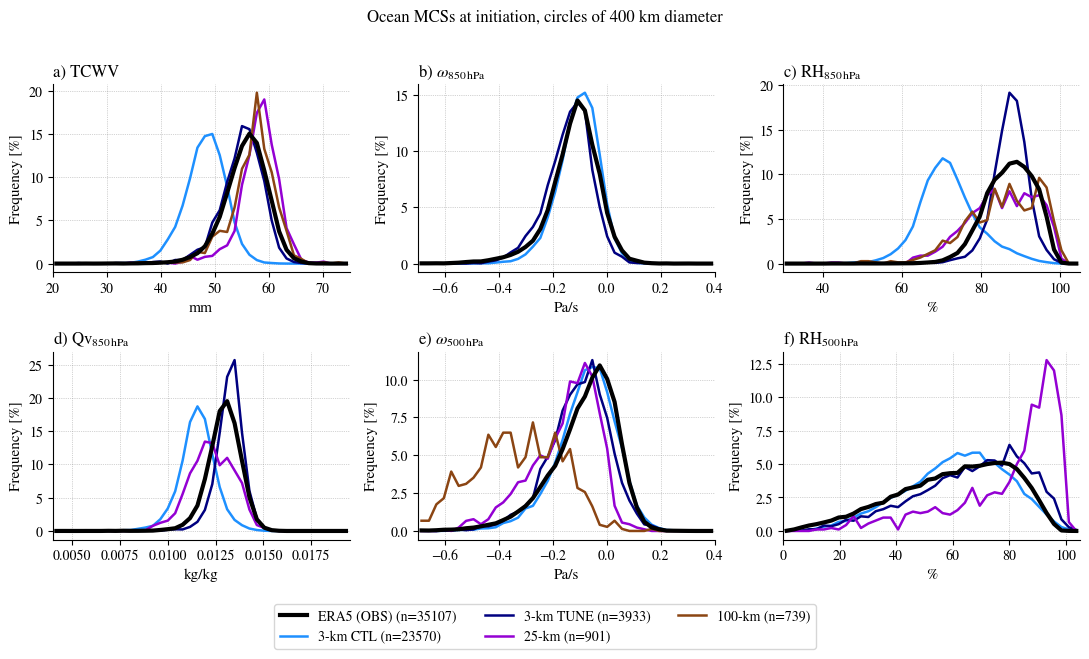

/pscratch/sd/f/feng045/mcs_env/figures/env_pdf_initiation_land.png


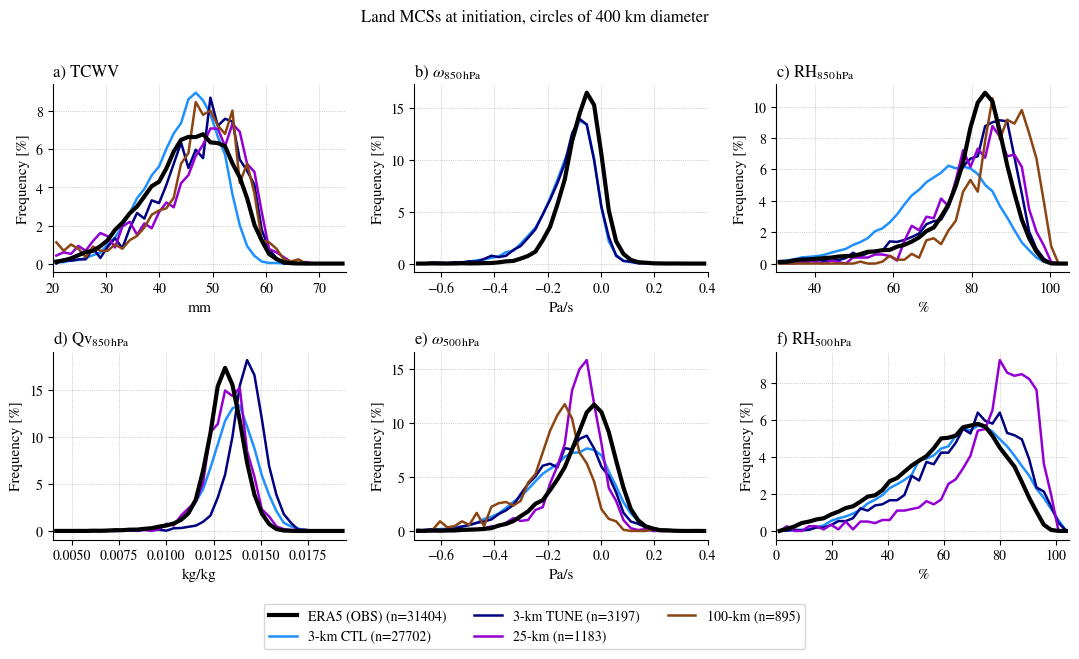

In [16]:
for surface in SURFACES:
    fig = plot_distributions(INIT, surface)
    print(save_figure(fig, f'env_pdf_initiation_{surface.lower()}.png'))
    plt.show()

### Median evolution around initiation (Fig. 5 of the paper)
Median over the robust tracks at every hour relative to initiation, the interquartile range of the reference source (ERA5) shaded. The circle is at the initial centroid before
initiation and follows the track afterwards.

/pscratch/sd/f/feng045/mcs_env/figures/env_evolution_median_ocean.png


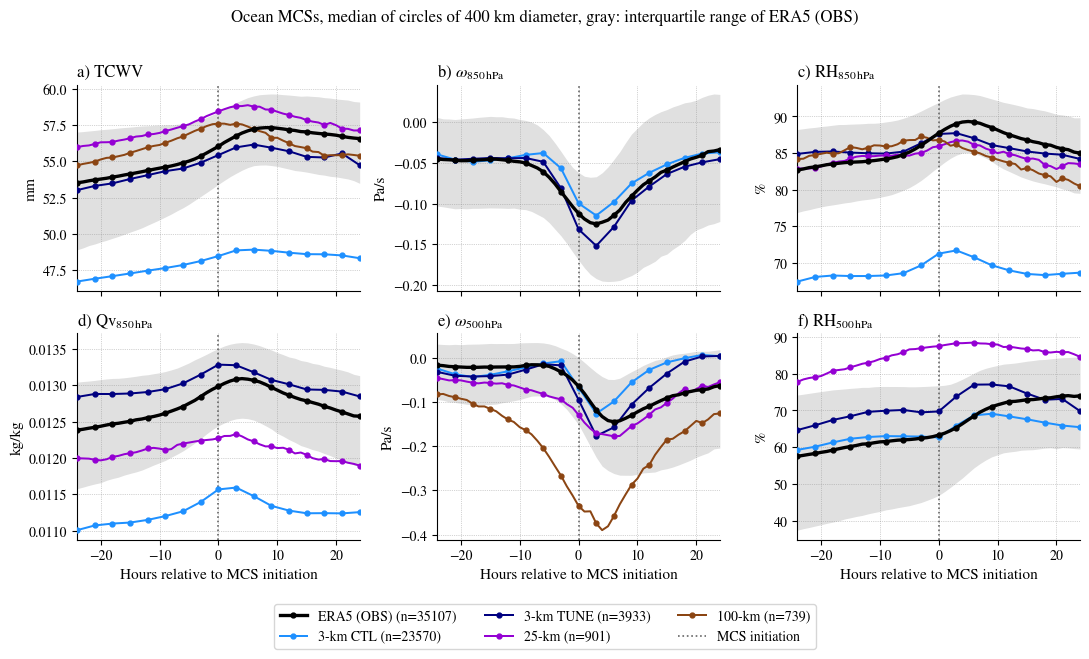

/pscratch/sd/f/feng045/mcs_env/figures/env_evolution_median_land.png


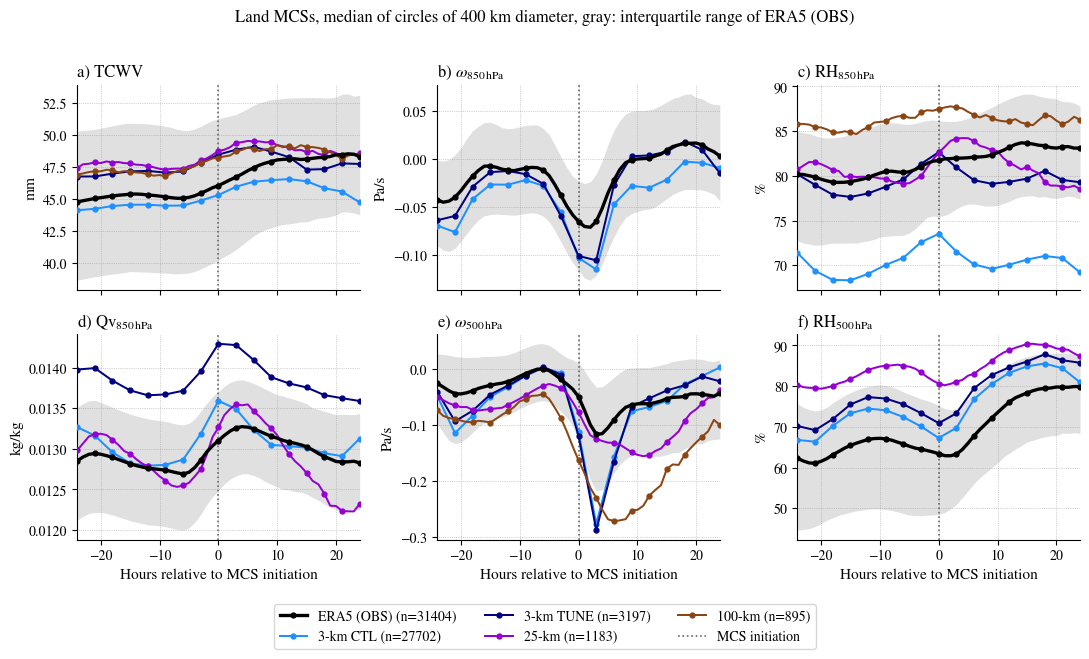

In [12]:
for surface in SURFACES:
    fig = plot_evolution(COMP, surface, stat='median')
    print(save_figure(fig, f'env_evolution_median_{surface.lower()}.png'))
    plt.show()

### Mean evolution (the statistic of `analyze_envvars_evolution.ipynb`) and ocean versus land

/pscratch/sd/f/feng045/mcs_env/figures/env_evolution_mean_ocean.png


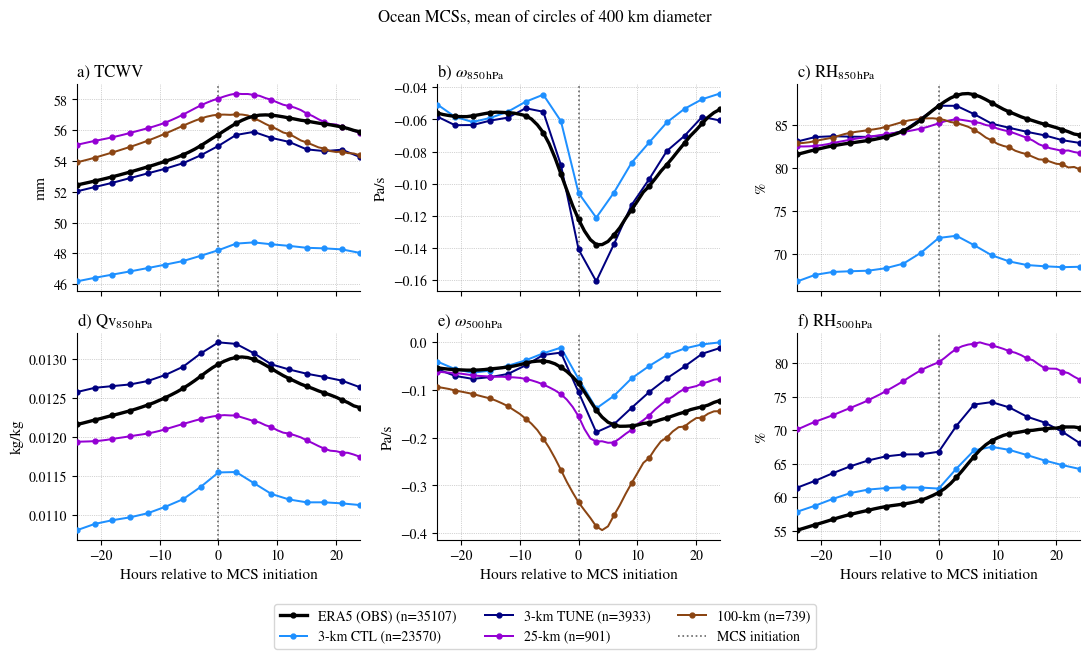

/pscratch/sd/f/feng045/mcs_env/figures/env_evolution_mean_land.png


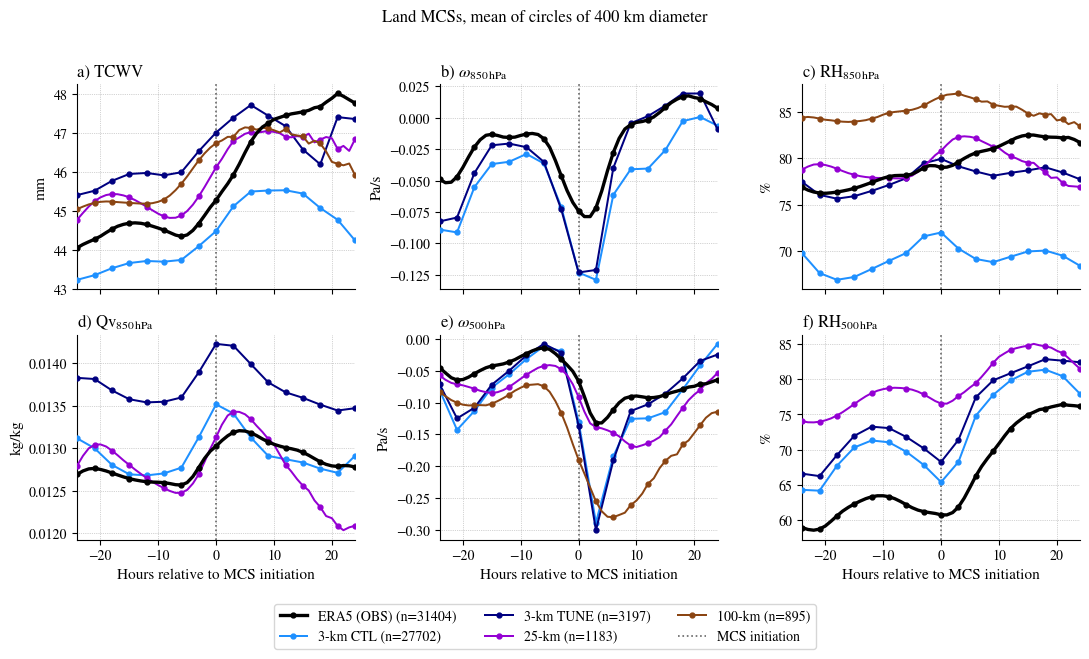

/pscratch/sd/f/feng045/mcs_env/figures/env_evolution_median_ocean_vs_land.png


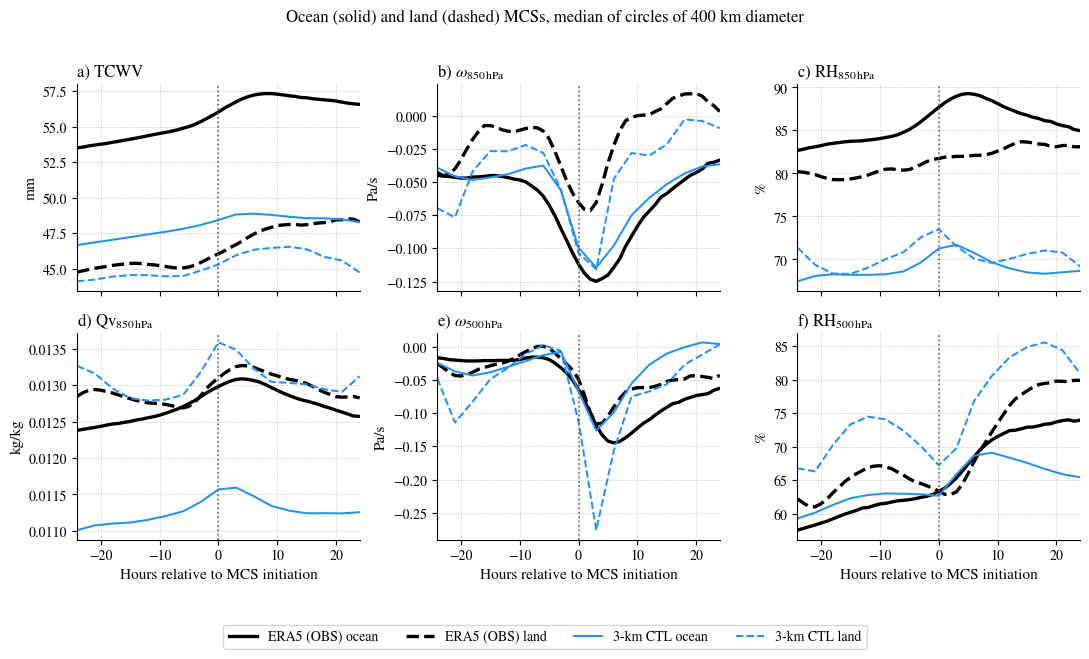

In [13]:
for surface in SURFACES:
    fig = plot_evolution(COMP, surface, stat='mean', band_source=None)
    print(save_figure(fig, f'env_evolution_mean_{surface.lower()}.png'))
    plt.show()

# Ocean and land in the same panels for the reference and the 3-km control run
fig = plot_surface_overlay(COMP, [REF_SOURCE, '3km_CTL'])
print(save_figure(fig, 'env_evolution_median_ocean_vs_land.png'))
plt.show()

## Key numbers
Median (and mean) at selected times, for the comparison with other analyses (for example the SCREAM and ERA5 curves of `analyze_envvars_evolution.ipynb`).

In [14]:
OFFSETS = [-24, 0, 6, 12]
for surface in SURFACES:
    for stat in ('median', 'mean'):
        print(f'{surface} MCSs, {stat} of the circle means at {OFFSETS} h relative to initiation:')
        display(key_numbers(COMP, surface, OFFSETS, stat).round(4))

Ocean MCSs, median of the circle means at [-24, 0, 6, 12] h relative to initiation:


ERA5 (OBS)                                    3-km CTL             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       53.519501  56.042198  57.237400  57.189400  46.676102  48.443001   
omega850  -0.044900  -0.112000  -0.114100  -0.071900  -0.039300  -0.099500   
rh850     82.677299  87.695702  89.207199  87.478500  67.463501  71.271599   
q850       0.012400   0.013000   0.013100   0.012900   0.011000   0.011600   
omega500  -0.016500  -0.064400  -0.144700  -0.109800  -0.024300  -0.067100   
rh500     57.604198  63.341702  68.501099  72.399696  59.344299  62.706699   

                                3-km TUNE                                   \
               6.0        12.0      -24.0       0.0        6.0        12.0   
variable                                                                     
prw       48.887901  48.675400  53.013599  55.442101  56.168701  55.703499   
omega850  -0.097800  -0.062000  -0.043700  -0.131400  -0.128400  -0.078800   
rh850     70.773903  68.978996  84.869301  87.587898  87.005699  85.652901   
q850       0.011500   0.011300   0.012800   0.013300   0.013200   0.013000   
omega500  -0.098700  -0.027200  -0.031700  -0.094900  -0.157400  -0.067900   
rh500     68.675201  68.389801  64.707001  69.736000  76.986198  76.520103   

              25-km                                      100-km             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       55.989700  58.467701  58.798302  58.220402  54.723202  57.621799   
omega850        NaN        NaN        NaN        NaN        NaN        NaN   
rh850     82.866402  85.916100  86.107597  84.836502  84.170502  86.775002   
q850       0.012000   0.012300   0.012200   0.012100        NaN        NaN   
omega500  -0.045500  -0.129300  -0.177600  -0.129100  -0.082700  -0.335400   
rh500     77.747101  87.401100  88.368103  87.243599        NaN        NaN   

                                
               6.0        12.0  
variable                        
prw       57.235600  56.262901  
omega850        NaN        NaN  
rh850     85.178299  83.652802  
q850            NaN        NaN  
omega500  -0.358300  -0.242700  
rh500           NaN        NaN

Ocean MCSs, mean of the circle means at [-24, 0, 6, 12] h relative to initiation:


ERA5 (OBS)                                    3-km CTL             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       52.443001  55.722198  56.917702  56.799301  46.180199  48.203701   
omega850  -0.056000  -0.122200  -0.131900  -0.101500  -0.050700  -0.105800   
rh850     81.595299  87.225700  88.523499  86.514397  66.824997  71.864799   
q850       0.012200   0.012900   0.013000   0.012800   0.010800   0.011500   
omega500  -0.053900  -0.086500  -0.173100  -0.168900  -0.040800  -0.077300   
rh500     55.113701  60.727600  66.097298  69.499001  57.876900  61.314800   

                                3-km TUNE                                   \
               6.0        12.0      -24.0       0.0        6.0        12.0   
variable                                                                     
prw       48.709599  48.483799  52.032200  54.982899  55.893101  55.242298   
omega850  -0.105500  -0.074300  -0.058200  -0.140900  -0.137700  -0.097100   
rh850     71.029701  69.130898  83.083801  87.232201  86.262604  84.665497   
q850       0.011400   0.011200   0.012600   0.013200   0.013100   0.012900   
omega500  -0.112600  -0.050100  -0.056800  -0.105100  -0.172100  -0.104600   
rh500     67.010399  67.082497  61.469200  66.807999  73.853104  73.418602   

              25-km                                      100-km             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       55.056702  58.063099  58.294399  57.574902  53.918499  57.012100   
omega850        NaN        NaN        NaN        NaN        NaN        NaN   
rh850     82.505302  85.186996  85.343597  84.236801  82.860901  85.696899   
q850       0.011900   0.012300   0.012200   0.012000        NaN        NaN   
omega500  -0.061800  -0.155500  -0.210200  -0.153700  -0.094000  -0.335300   
rh500     70.150703  80.161102  82.922897  81.802803        NaN        NaN   

                                
               6.0        12.0  
variable                        
prw       56.776199  55.756802  
omega850        NaN        NaN  
rh850     84.434799  82.399803  
q850            NaN        NaN  
omega500  -0.362600  -0.242300  
rh500           NaN        NaN

Land MCSs, median of the circle means at [-24, 0, 6, 12] h relative to initiation:


ERA5 (OBS)                                    3-km CTL             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       44.778900  46.058399  47.447102  48.129299  44.127998  45.316399   
omega850  -0.042800  -0.065600  -0.022400   0.000600  -0.069700  -0.103500   
rh850     80.194801  81.738998  82.104599  83.202400  71.380096  73.524803   
q850       0.012900   0.013100   0.013200   0.013100   0.013300   0.013600   
omega500  -0.025200  -0.049100  -0.090300  -0.061600  -0.047800  -0.112600   
rh500     62.271599  63.421101  67.792099  76.113899  66.790100  67.265602   

                                3-km TUNE                                   \
               6.0        12.0      -24.0       0.0        6.0        12.0   
variable                                                                     
prw       46.353600  46.559700  46.758099  48.464901  49.073502  48.266800   
omega850  -0.047600  -0.030100  -0.064100  -0.101500  -0.027500   0.003600   
rh850     70.098999  70.068001  80.174599  82.644997  79.516098  79.331497   
q850       0.013200   0.013000   0.014000   0.014300   0.014100   0.013800   
omega500  -0.156100  -0.067400  -0.040200  -0.119600  -0.165300  -0.051800   
rh500     76.791100  83.269501  70.198898  70.902496  79.477798  84.624702   

              25-km                                      100-km             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       47.421501  48.754002  49.492001  49.039001  46.913799  48.237400   
omega850        NaN        NaN        NaN        NaN        NaN        NaN   
rh850     80.713799  82.574600  83.878799  81.444099  85.823997  87.476303   
q850       0.013000   0.013300   0.013500   0.012900        NaN        NaN   
omega500  -0.049800  -0.077000  -0.131500  -0.153700  -0.073300  -0.162900   
rh500     80.286598  80.623100  82.992996  88.835098        NaN        NaN   

                                
               6.0        12.0  
variable                        
prw       48.901699  49.152302  
omega850        NaN        NaN  
rh850     86.824600  86.079498  
q850            NaN        NaN  
omega500  -0.271500  -0.225900  
rh500           NaN        NaN

Land MCSs, mean of the circle means at [-24, 0, 6, 12] h relative to initiation:


ERA5 (OBS)                                    3-km CTL             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       44.058201  45.278198  46.779701  47.452499  43.235199  44.486000   
omega850  -0.049000  -0.074200  -0.027800  -0.001800  -0.089000  -0.123200   
rh850     76.874397  79.007797  80.586700  81.893204  69.756203  71.996101   
q850       0.012700   0.013000   0.013200   0.013000   0.013100   0.013500   
omega500  -0.045400  -0.066300  -0.111200  -0.092600  -0.080600  -0.130000   
rh500     58.903599  60.717602  66.236603  73.001701  64.276001  65.374702   

                                3-km TUNE                                   \
               6.0        12.0      -24.0       0.0        6.0        12.0   
variable                                                                     
prw       45.500198  45.533298  45.409401  47.014999  47.720501  47.179199   
omega850  -0.061400  -0.040500  -0.082500  -0.123200  -0.040000   0.001300   
rh850     69.140999  69.385002  77.436203  79.933701  78.574997  78.429001   
q850       0.013100   0.012900   0.013800   0.014200   0.014000   0.013700   
omega500  -0.184600  -0.124800  -0.071700  -0.136300  -0.190900  -0.102800   
rh500     74.821602  79.846199  66.575600  68.249001  77.440804  80.864998   

              25-km                                      100-km             \
              -24.0       0.0        6.0        12.0      -24.0       0.0    
variable                                                                     
prw       44.778702  46.123501  47.024399  46.908298  45.049198  46.743000   
omega850        NaN        NaN        NaN        NaN        NaN        NaN   
rh850     78.782402  80.807404  82.176697  80.218597  84.388100  86.640404   
q850       0.012800   0.013100   0.013300   0.012800        NaN        NaN   
omega500  -0.057500  -0.091500  -0.147700  -0.164000  -0.083900  -0.189900   
rh500     74.049698  76.561600  79.452599  84.197403        NaN        NaN   

                                
               6.0        12.0  
variable                        
prw       47.131500  47.103001  
omega850        NaN        NaN  
rh850     86.360397  85.574600  
q850            NaN        NaN  
omega500  -0.280000  -0.227500  
rh500           NaN        NaN

## Notes on the comparison with the GSRM repository notebook
*Record of the first analysis (2026-11-21; ERA5 2007-2017, 3-km CTL 1995-2005, 3-km TUNE 2019-08 ... 2021-03, 25-km 2009-2011, 100-km 2009-2020). The text does not change when the notebook is run again.*

**Reference.** Ocean composites of Laura Paccini's SCREAM Cess1 run (2019-08 ... 2020-09, the settings of the 3-km CTL run) and of ERA5 2020: 2-degree radius, her filter (1,936 and 2,825 tracks). Her curves were rebuilt from her
environment files with `composite_by_offset` (it gives exactly the numbers of `evolution_by_radius`); her ERA5 RH850 and RH500 files are empty on her scratch, so those two are not compared. The functions of this notebook with her
options (`n_nonmcs=3, continuity='mcs_duration', split_merge='status', ocean_rule='sum', duration_pct=None`) reproduce her two saved track lists **exactly** (the repository code used three initial non-MCS steps, the paper two).

**Median, ocean, this notebook (400-km diameter, paper wording of the criteria) against hers**

| | 3-km CTL against her SCREAM at 0 / +6 / +12 h | ERA5 2007-2017 against her ERA5 2020 |
|---|---|---|
| TCWV | -2 / -3 / -3 % (agree to 1.7 mm; both are 7-8 mm below ERA5) | -0.3 / -0.4 / -0.5 % |
| RH850 | -1 / -1 / -1 % | not available |
| Qv850 | +2 / 0 / 0 % (the 3-km Qv850 is derived from T and RH, a +2 % bias was measured for this derivation on E3SM data) | -1 / -1 / 0 % |
| omega850 | +8 / -6 / -6 % | -9 / -10 / -4 % |
| omega500 | ascent +16 % stronger at 0 h, 20 % weaker at +6 h, 40 % weaker at +12 h | ascent 15 / 9 / 14 % weaker |
| RH500 | +7 / +7 / +5 % | not available |

* **Same shapes and almost the same numbers for the moisture variables** (TCWV, Qv850, RH850): the 3-km CTL run reproduces the SCREAM Cess1 composites, so the environment extraction, the nominal relative-time grid and the 400-km circle give what the earlier workflow gave.
* **omega500 after initiation is weaker here than in hers** (both for SCREAM and ERA5). Tests with this notebook's functions (ocean, 3-km CTL median): the filter choices matter little (her three initial steps move the +6 h value from -0.099 to -0.109, hers is -0.123;
  `mcs_duration` instead of the unbroken block changes nothing visible), the **circle size matters a lot** (omega500 at 0 h: -0.161 / -0.067 / -0.036 Pa/s for 200 / 400 / 600 km diameter; a 2-degree radius is a 444-km diameter, which gives about -0.057 to -0.060 by interpolation, hers is -0.058), and the rest
  probably comes from the different MCS track sets and periods (MCSMIP tracks 2007-2017 against the Cess1 / 2020 tracks of the repository).
* **The criteria change the number of tracks, not the composites.** The choices of the repository code give 7 % (ERA5) and 11 % (3-km CTL) fewer ocean tracks, but 24 % and 46 % fewer land tracks, and 66 % fewer ocean tracks in the 100-km run (three initial non-MCS steps are rarely met there); see the variants table.
* **Model biases that the figures show** (median, ocean, 0 h): 3-km CTL TCWV 48 mm and RH850 71 % against 56 mm and 88 % in ERA5 (the 3-km TUNE run is close to ERA5: 55 mm, 88 %); 25-km RH500 87 % against 63 % in ERA5 (RH500 is derived from T500 and Q500) and TCWV 2.4 mm too high; 100-km omega500 -0.34 Pa/s against -0.065 in ERA5.
* **Coverage.** 3-km TUNE TCWV is valid for 43 % of the tracks only (the `ne120pg2` stream ends 2020-04-10); the 850 hPa variables of land tracks are valid at initiation for 96 % (ERA5), 88 % (25-km) and 90 % (100-km) of the tracks (the other circles are mostly below the ground, `MIN_VALIDFRAC`); the 100-km run has no Qv850, RH500 and omega850, the 25-km run no omega850.